# FASE 1. COMPRENSIÓN DE LOS DATOS - RUIDO (sonómetros)

## 1. Carga y observaciones iniciales

In [7]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("TFM_Ruido_Valencia") \
    .getOrCreate()

print("Spark funcionando correctamente")
print("Versión de Spark:", spark.version)

Spark funcionando correctamente
Versión de Spark: 3.3.2


In [8]:
# Nombre de nuestro bucket
bucket = "gs://tfm_unir1"

# Ruta donde están los datos
ruta_ruido = f"{bucket}/ruido/"

# Acceder al sistema de archivos de Google Cloud Storage
path = spark._jvm.org.apache.hadoop.fs.Path(ruta_ruido)

fs = path.getFileSystem(spark._jsc.hadoopConfiguration())

# Listar archivos entrando a subcarpetas
iterador = fs.listFiles(path, True)

archivos = []

while iterador.hasNext():
    archivos.append(iterador.next().getPath().toString())
    
print("Número de elementos encontrados:", len(archivos))

for archivo in archivos[:10]:
    print(archivo)

Número de elementos encontrados: 20
gs://tfm_unir1/ruido/entities.csv
gs://tfm_unir1/ruido/ruido_limpio/_SUCCESS
gs://tfm_unir1/ruido/ruido_limpio/part-00000-dbd5ab25-03f3-4978-a513-900b9e3d9d61-c000.snappy.parquet
gs://tfm_unir1/ruido/ruido_limpio/part-00001-dbd5ab25-03f3-4978-a513-900b9e3d9d61-c000.snappy.parquet
gs://tfm_unir1/ruido/ruido_limpio/part-00002-dbd5ab25-03f3-4978-a513-900b9e3d9d61-c000.snappy.parquet
gs://tfm_unir1/ruido/ruido_limpio/part-00003-dbd5ab25-03f3-4978-a513-900b9e3d9d61-c000.snappy.parquet
gs://tfm_unir1/ruido/ruido_limpio/part-00004-dbd5ab25-03f3-4978-a513-900b9e3d9d61-c000.snappy.parquet
gs://tfm_unir1/ruido/ruido_limpio/part-00005-dbd5ab25-03f3-4978-a513-900b9e3d9d61-c000.snappy.parquet
gs://tfm_unir1/ruido/ruido_limpio/part-00006-dbd5ab25-03f3-4978-a513-900b9e3d9d61-c000.snappy.parquet
gs://tfm_unir1/ruido/ruido_limpio/part-00007-dbd5ab25-03f3-4978-a513-900b9e3d9d61-c000.snappy.parquet


## 2. Análisis de archivos 

In [9]:
redes = {
    "ruido_bsg":     "gs://tfm_unir1/ruido/sonometros_noiselevelobserved_bsg.csv",
    "ruido_dipuval": "gs://tfm_unir1/ruido/sonometros_noiselevel_dipuval_quincemin.csv",
    "ruido_zas":     "gs://tfm_unir1/ruido/sonometros_noiselevelobserved_ayto_zas_rt.csv",
    "ruido_hopu":    "gs://tfm_unir1/ruido/sonometros_noiselevelobserved_impulso_hopu_rt.csv",
    "ruido_ruzafa":  "gs://tfm_unir1/ruido/sonometros_noiselevelobserved_ruzafa_elecnor_rt.csv"
}

for nombre, archivo in redes.items():
    spark.read.csv(archivo, header=True).createOrReplaceTempView(nombre)
    print("Vista creada:", nombre)

Vista creada: ruido_bsg
Vista creada: ruido_dipuval
Vista creada: ruido_zas
Vista creada: ruido_hopu
Vista creada: ruido_ruzafa


In [10]:
# Unificamos todas las vistas en una, y sólo nos quedamos con los campos necesarios: red, sensor, nivel de ruido y fecha

spark.sql ("""
    CREATE OR REPLACE TEMP VIEW ruido_unificado AS
        SELECT 'bsg'     AS red, entityId AS id_sensor, CAST(LAeq AS DOUBLE) AS laeq, CAST(calculatedTimestamp AS TIMESTAMP) AS fecha_hora FROM ruido_bsg
    UNION ALL
        SELECT 'dipuval'     AS red, entityId AS id_sensor, CAST(LAeq AS DOUBLE) AS laeq, CAST(dateObserved AS TIMESTAMP) AS fecha_hora FROM ruido_dipuval
    UNION ALL
        SELECT 'zas'     AS red, entityId AS id_sensor, CAST(LAeq AS DOUBLE) AS laeq, CAST(dateObserved AS TIMESTAMP) AS fecha_hora FROM ruido_zas
    UNION ALL
        SELECT 'hopu'     AS red, entityId AS id_sensor, CAST(LAeq AS DOUBLE) AS laeq, CAST(calculatedTimestamp AS TIMESTAMP) AS fecha_hora FROM ruido_hopu
    UNION ALL
        SELECT 'ruzafa'     AS red, entityId AS id_sensor, CAST(LAeq AS DOUBLE) AS laeq, CAST(calculatedTimestamp AS TIMESTAMP) AS fecha_hora FROM ruido_ruzafa
""")

spark.sql("""
    SELECT  red,
            COUNT(*)                         AS registros,
            COUNT(DISTINCT id_sensor)        AS sensores,
            CAST (MIN(fecha_hora) AS STRING) AS desde,
            CAST (MAX(fecha_hora) AS STRING) AS hasta
    FROM ruido_unificado
    GROUP By red
    ORDER BY red           
""").toPandas()

,red,registros,sensores,desde,hasta
0,bsg,2358599,2,2024-04-18 06:21:00,2026-06-05 09:45:00
1,dipuval,1452263,88,2025-02-11 09:18:02,2026-11-05 12:59:06
2,hopu,21366791,22,1975-06-02 09:02:50,2033-12-31 11:51:29
3,ruzafa,20758441,17,2024-04-18 06:28:38,2026-06-05 10:01:05
4,zas,16761605,18,2024-01-08 08:05:46,2026-11-04 09:04:00


**Observaciones:** 
- Hay mas de 62 millones de registros y 147 sensores. 
- Tenemos que analizar hopu por los valores minimos y maximos de los registros
- Los períodos son distintos en cada red

Analizaremos registros por red y año para entender con qué franja de datos nos quedamos

### Distribución anual de los registros

In [11]:
# Ver cantidades de registros por año
spark.sql("""
    SELECT red,
        YEAR (fecha_hora) AS anio,
        COUNT(*) AS registros
    FROM ruido_unificado
    GROUP BY red, YEAR (fecha_hora)
    ORDER BY red, anio
""").toPandas()

,red,anio,registros
0,bsg,NaN,423027
1,bsg,2024.0,731134
2,bsg,2025.0,872799
3,bsg,2026.0,331639
4,dipuval,NaN,20
5,dipuval,2025.0,654806
6,dipuval,2026.0,797437
7,hopu,NaN,4004099
8,hopu,1975.0,8
9,hopu,1987.0,5


- Tenemos concentracion de datos en todas las redes desde el 2024 hasta 2026
- Hay varias fechas NaN. Vamos a analizar si estamos perdiendo datos al castear
- En principio tomaremos los datos de 2024 y 2025 para usar el mismo período de análisis de los otros factores.

In [12]:
spark.sql("""
    SELECT 'ruzafa' AS red,
           SUM(CASE WHEN calculatedTimestamp IS NULL THEN 1 ELSE 0 END) AS sin_fecha_original,
           SUM(CASE WHEN CAST(calculatedTimestamp AS TIMESTAMP) IS NULL THEN 1 ELSE 0 END) AS sin_fecha_convertida
    FROM ruido_ruzafa
    UNION ALL
    SELECT 'bsg',
           SUM(CASE WHEN calculatedTimestamp IS NULL THEN 1 ELSE 0 END),
           SUM(CASE WHEN CAST(calculatedTimestamp AS TIMESTAMP) IS NULL THEN 1 ELSE 0 END)
    FROM ruido_bsg
""").toPandas()

,red,sin_fecha_original,sin_fecha_convertida
0,ruzafa,2917891,2917891
1,bsg,423027,423027


Las fechas NaN venian vacias en los archivos originales con lo cual, eliminar los registros es la decision adecuada, ya que no estamos perdiendo informacion.
Entonces nuestra vista solo tendra registros de 2024 y 2025 sin incluir nulos

In [13]:
spark.sql("""
    CREATE OR REPLACE TEMP VIEW ruido_2024_2025 AS
    SELECT *
    FROM ruido_unificado
    WHERE YEAR(fecha_hora) IN (2024, 2025)
""")

spark.sql("""
    SELECT red,
           COUNT(*)                  AS registros,
           COUNT(DISTINCT id_sensor) AS sensores
    FROM ruido_2024_2025
    GROUP BY red
    ORDER BY red
""").toPandas()

,red,registros,sensores
0,bsg,1603933,2
1,dipuval,654806,84
2,hopu,14110015,22
3,ruzafa,14199202,17
4,zas,13146906,18


### Evaluación inicial de la calidad de los datos

In [14]:
# Valores vacíos y rango

spark.sql ("""
    SELECT red,
            COUNT(*)                                       AS registros,
            SUM(CASE WHEN laeq IS NULL THEN 1 ELSE 0 END)  AS laeq_vacio,
            ROUND (MIN(laeq),1)                            AS minimo,
            ROUND(PERCENTILE_APPROX(laeq, 0.5), 1)         AS mediana,
            ROUND (MAX(laeq),1)                            AS maximo
    FROM ruido_2024_2025
    GROUP BY red
    ORDER BY red       
"""). toPandas()


,red,registros,laeq_vacio,minimo,mediana,maximo
0,bsg,1603933,0,3.290000e+01,53.9,119.4
1,dipuval,654806,1,4.900000e+01,59.0,111.9
2,hopu,14110015,0,-9.223372e+18,61.3,187.4
3,ruzafa,14199202,0,1.260000e+01,57.5,115.5
4,zas,13146906,4589,2.430000e+01,59.0,768.3


- Hay pocos vacíos.
- Hay valores de error que guarda el sistema cuando el sensor no tiene dato.
- Las medianas estan entre 54 y 61 dB, valores normales en una ciudad.
- Hay algunos máximos a revisar.

In [15]:
# Revisamos valores de maximos y minimos para fijar un rango válido de observaciones
# 20 dB es más silencio que un susurro. Pro encima de 140 dB es mas que un avión despegando
spark.sql("""
    SELECT red,
           COUNT(*)                                                  AS registros,
           SUM(CASE WHEN laeq < 20  THEN 1 ELSE 0 END)               AS menor_20,
           SUM(CASE WHEN laeq > 140 THEN 1 ELSE 0 END)               AS mayor_140,
           ROUND(SUM(CASE WHEN laeq < 20 OR laeq > 140 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 3) AS pct_fuera
    FROM ruido_2024_2025
    GROUP BY red
    ORDER BY red
""").toPandas()

,red,registros,menor_20,mayor_140,pct_fuera
0,bsg,1603933,0,0,0.000
1,dipuval,654806,0,0,0.000
2,hopu,14110015,1,3,0.000
3,ruzafa,14199202,246,0,0.002
4,zas,13146906,0,29,0.000


Los registros fuera de rango son un total de 279 registros que sumados a los vacios (4600) representan menos del 0.01% de los datos. 
Limpiaremos datos luego de finalizar el análisis

**Limpieza:** Elimnar valores fuera de rango y vacíos

### Identificación de periodos con mediciones inválidas / congelados

In [16]:
# Veamos valores congelados. 
# Contamos la cantidad de veces que aparece un valor. Si aparece muchisimas veces, es un valor congelado

spark.sql ("""
    SELECT red, id_sensor, laeq, COUNT(*) AS veces
    FROM ruido_2024_2025
    GROUP BY red, id_sensor, laeq
    ORDER BY veces DESC
    LIMIT 15
"""). toPandas()



,red,id_sensor,laeq,veces
0,bsg,2693,46.2,418044
1,bsg,2699,46.2,338994
2,ruzafa,T248683,61.1,12011
3,ruzafa,T248683,61.3,12003
4,ruzafa,T248683,61.0,11982
5,ruzafa,T248683,61.4,11844
6,ruzafa,T248683,60.9,11804
7,ruzafa,T248683,61.2,11725
8,zas,sonzas2236man,61.7,11711
9,ruzafa,T248683,61.5,11662


En BSG, el valor 46.2 DB aparece mas de 700000 veces entre sus dos sensores. Casi la mitas de sus registros. Como no es posbile saber qué datos de esta red son válidos, se deja de lado BSG. En el resto de las redes no se observan valores congelados.

**Limpieza:*** Eliminar valores de BSG porque no sabemos si los datos obtenidos son certeros.

In [18]:
# Vemos valor duplicados

spark.sql("""
    SELECT red, id_sensor, CAST(fecha_hora AS STRING) AS fecha_hora, COUNT(*) AS veces
    FROM ruido_2024_2025
    GROUP BY red, id_sensor, fecha_hora
    HAVING COUNT(*) > 1
    ORDER BY veces DESC
    LIMIT 15
""").toPandas()


,red,id_sensor,fecha_hora,veces
0,hopu,NoiseLevelObserved-HOPVLCi4,2025-08-16 16:16:30,6
1,hopu,NoiseLevelObserved-HOPVLCi19,2025-05-18 16:30:27,5
2,hopu,NoiseLevelObserved-HOPVLCi13,2025-10-09 07:46:25,5
3,hopu,NoiseLevelObserved-HOPVLCi16,2025-02-19 09:35:33,5
4,hopu,NoiseLevelObserved-HOPVLCi14,2025-02-27 08:54:07,5
5,hopu,NoiseLevelObserved-HOPVLCi16,2025-01-27 22:12:46,5
6,hopu,NoiseLevelObserved-HOPVLCi16,2025-12-17 05:33:47,5
7,hopu,NoiseLevelObserved-HOPVLCi5,2025-06-30 17:39:33,5
8,hopu,NoiseLevelObserved-HOPVLCi16,2025-07-15 05:57:32,5
9,hopu,NoiseLevelObserved-HOPVLCi4,2025-07-20 17:57:00,5


Exception in thread "serve-DataFrame" java.net.SocketTimeoutException: Accept timed out
	at java.base/java.net.PlainSocketImpl.socketAccept(Native Method)
	at java.base/java.net.AbstractPlainSocketImpl.accept(AbstractPlainSocketImpl.java:474)
	at java.base/java.net.ServerSocket.implAccept(ServerSocket.java:565)
	at java.base/java.net.ServerSocket.accept(ServerSocket.java:533)
	at org.apache.spark.security.SocketAuthServer$$anon$1.run(SocketAuthServer.scala:64)


**Observaciones:** 
Se detectan registros duplicados (mismo sensor, mismo momento), principalmente en HOPU y en ZAS, con hasta 6 repeticiones

**Limpieza:**
En la limpieza eliminaremos filas repetidas

**Conclusiones:**
 - Solo utlizaremos datos de 2024 y 2025
 - Eliminaremos LAeq vacío y fuera del rango 20-140 dB
 - Quitar 46,2 de BAG que aparece como valor congelado
 - Eliminar duplicados

### Armamos vista limpia

In [16]:
spark.sql("""
    CREATE OR REPLACE TEMP VIEW ruido_limpio AS
    SELECT DISTINCT red, id_sensor, laeq, fecha_hora
    FROM ruido_2024_2025
    WHERE laeq BETWEEN 20 AND 140
      AND red <> 'bsg'
""")

spark.sql("""
    SELECT red,
           COUNT(*)                  AS registros,
           COUNT(DISTINCT id_sensor) AS sensores
    FROM ruido_limpio
    GROUP BY red
    ORDER BY red
""").toPandas()

,red,registros,sensores
0,dipuval,654747,84
1,hopu,14033370,22
2,ruzafa,14198912,17
3,zas,12818418,18


Quedan en total 41,7 millones de registos.

In [17]:
# Guardamos los datos limpios para no recalcular todo en cada consulta
spark.table("ruido_limpio").write.mode("overwrite").parquet("gs://tfm_unir1/ruido/ruido_limpio")

In [18]:
# Desde ahora leemos del Parquet
spark.read.parquet("gs://tfm_unir1/ruido/ruido_limpio").createOrReplaceTempView("ruido_limpio")

### Análisis exploratorio preliminar

In [21]:
# Primeras estadísticas descriptivas - ACA
import pandas as pd

df = spark.table("ruido_limpio")

columnas = []
for red in ["dipuval", "hopu", "ruzafa", "zas"]:
    resumen = df.filter(df.red == red).select("laeq").summary().toPandas()
    resumen = resumen.set_index("summary")["laeq"].astype(float).round(1)
    resumen.name = red
    columnas.append(resumen)

estadisticas = pd.concat(columnas, axis=1)
estadisticas


,dipuval,hopu,ruzafa,zas
summary,,,,
count,654747.0,14033370.0,14198912.0,12818418.0
mean,59.9,61.2,56.2,57.7
stddev,4.9,7.0,7.8,8.1
min,49.0,29.0,20.0,24.3
25%,56.5,56.5,52.5,53.2
50%,59.0,61.3,57.5,59.0
75%,63.6,65.9,61.2,62.8
max,111.9,119.3,115.5,117.3


- Las cuatro redes tienen niveles parecidos: la mediana va de 57,5 dB (Ruzafa) a 61,3 dB (HOPU), y la media de 56,2 a 61,2 dB.
- La mitad de las mediciones está aproximadamente entre 53 y 66 dB (entre el percentil 25 y el 75).
- La media y la mediana son muy parecidas: a diferencia del tráfico, el ruido no tiene una distribución muy asimétrica. En Ruzafa y ZAS la media queda algo por debajo de la mediana, porque hay más valores bajos (horas tranquilas).

/tmp/ipykernel_4167/2728696015.py:16: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  eje.bxp(cajas, showfliers=False, patch_artist=True,


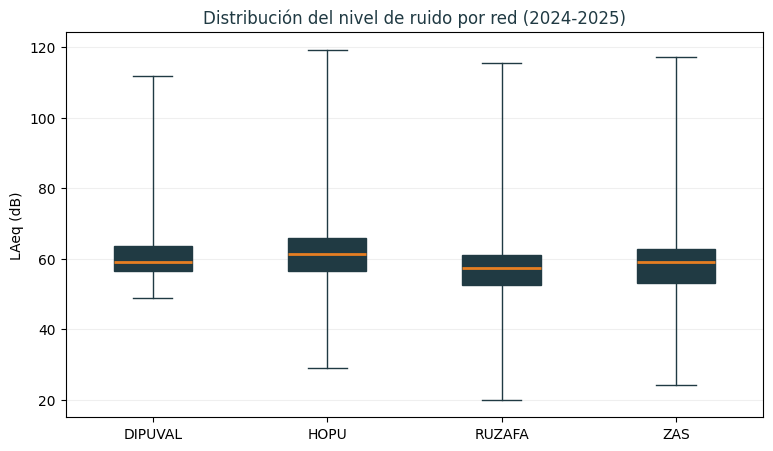

In [22]:
import matplotlib.pyplot as plt

cajas = []
for red in estadisticas.columns:
    cajas.append({
        "label":   red.upper(),
        "whislo":  estadisticas.loc["min", red],   # bigote inferior
        "q1":      estadisticas.loc["25%", red],   # borde inferior de la caja
        "med":     estadisticas.loc["50%", red],   # mediana
        "q3":      estadisticas.loc["75%", red],   # borde superior de la caja
        "whishi":  estadisticas.loc["max", red],   # bigote superior
        "fliers":  []                              # sin puntos sueltos
    })

fig, eje = plt.subplots(figsize=(9, 5))
eje.bxp(cajas, showfliers=False, patch_artist=True,
        boxprops=dict(facecolor="#56747B", color="#203A43"),
        medianprops=dict(color="#E67E22", linewidth=2),
        whiskerprops=dict(color="#203A43"),
        capprops=dict(color="#203A43"))

eje.set_title("Distribución del nivel de ruido por red (2024-2025)", color="#203A43")
eje.set_ylabel("LAeq (dB)")
eje.grid(axis="y", alpha=0.2)
plt.show()

## 3. Caracterizaciones adicionales del conjunto completo 

Hemos hecho un analisis inicial de todo el conjunto de datos. 
Agregamos algunas análisis adicionales que puedan ser de utilidad para el TFM.

### Análisis de cobertura espacial y temporal

In [23]:
# Cobertura por mes y red

cobertura = spark.sql("""
    SELECT red,
           DATE_FORMAT(fecha_hora, 'yyyy-MM') AS mes,
           COUNT(*) AS registros
    FROM ruido_limpio
    GROUP BY red, DATE_FORMAT(fecha_hora, 'yyyy-MM')
""").toPandas()

cobertura.pivot(index="mes", columns="red", values="registros").fillna(0).astype(int)

red,dipuval,hopu,ruzafa,zas
mes,,,,
2024-01,0,0,0,537648
2024-02,0,0,0,653645
2024-03,0,0,0,503800
2024-04,0,342498,278366,341286
2024-05,0,854602,695704,647227
2024-06,0,805160,682651,566896
2024-07,0,829144,711755,629917
2024-08,0,852764,709460,655315
2024-09,0,724140,690279,638833


***Observaciones:***
Una vez que cada red empieza a medir, no hay meses sin datos. ZAS cubre 2024 y 2025 completos; HOPU y Ruzafa empiezan en abril de 2024 y DipuVal en febrero de 2025. Algunos meses tienen menos registros (por ejemplo, ZAS a final de 2025), pero ninguno queda vacío.

In [24]:
### Sensores coinciden con entities

In [25]:
# entities.csv es la ficha de cada sensor que contiene su location y que nos permitirá obtener su distrito
spark.read.csv("gs://tfm_unir1/ruido/entities.csv", header=True).createOrReplaceTempView("sensores")

spark.sql("""
    SELECT r.red,
           COUNT(DISTINCT r.id_sensor) AS sensores,
           COUNT(DISTINCT s.entityID)  AS encontrados_en_entities
    FROM ruido_limpio r
    LEFT JOIN sensores s
           ON r.id_sensor = s.entityID
    GROUP BY r.red
    ORDER BY r.red
""").toPandas()

26/11/22 16:57:12 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


,red,sensores,encontrados_en_entities
0,dipuval,84,84
1,hopu,22,20
2,ruzafa,17,17
3,zas,18,16


137 de 141 coinciden. Faltan 4 sensores, 2 de HOPU y 2 de ZAS

In [26]:
spark.sql("""
    SELECT r.red, r.id_sensor, COUNT(*) AS registros
    FROM ruido_limpio r
    LEFT JOIN sensores s
           ON r.id_sensor = s.entityID
    WHERE s.entityID IS NULL
    GROUP BY r.red, r.id_sensor
    ORDER BY r.red
""").toPandas()

,red,id_sensor,registros
0,hopu,NoiseLevelObserved-HOPVLCi20,173745
1,hopu,NoiseLevelObserved-HOPVLCi1,283288
2,zas,sonzas2250l22,5490
3,zas,sonzas2245c13,10092


En total, son 472600 registros, el 1.1%.Se descartaran estos en la preparacion de datos